Cargar el dataset principal

Pipeline usando pandas.

In [2]:
import pandas as pd

# Cargar la pestaña unificada
df = pd.read_excel('../data/raw/BASE DE DATOS.xlsx', sheet_name='Base_Unificada_2012_2025')

# Inspeccionar información general
print(df.info())
print(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 10225 entries, 0 to 10224
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Origen Datos                 10225 non-null  str    
 1   Año Firma                    10225 non-null  int64  
 2   Nombre Entidad               10225 non-null  str    
 3   NIT Entidad                  10225 non-null  str    
 4   Departamento                 10225 non-null  str    
 5   Municipio / Ciudad           10225 non-null  str    
 6   Orden Entidad                10225 non-null  str    
 7   Número de Proceso            10225 non-null  object 
 8   ID Contrato / Num. Contrato  10225 non-null  object 
 9   Estado Contrato              10225 non-null  str    
 10  Modalidad Contratación       10225 non-null  str    
 11  Tipo Contrato                10225 non-null  str    
 12  Objeto del Contrato          10225 non-null  str    
 13  Fecha Firma                

Resumen de contratación por año (Cantidad y Valor Total)

In [3]:
resumen_anual = df.groupby('Año Firma').agg(
    Cant_Contratos=('ID Contrato / Num. Contrato', 'count'),
    Valor_Total_COP=('Valor Contrato (COP)', 'sum'),
    Valor_Promedio_COP=('Valor Contrato (COP)', 'mean')
).reset_index()

# Formatear valores numéricos a moneda
resumen_anual['Valor_Total_COP_Formato'] = resumen_anual['Valor_Total_COP'].map('${:,.2f}'.format)
print(resumen_anual)

    Año Firma  Cant_Contratos  Valor_Total_COP  Valor_Promedio_COP  \
0        2012             187     7.615806e+10        4.072624e+08   
1        2013             413     7.500757e+10        1.816164e+08   
2        2014             471     2.079753e+11        4.415612e+08   
3        2015             518     2.462701e+11        4.754249e+08   
4        2016             529     9.182605e+10        1.735842e+08   
5        2017             599     1.033558e+11        1.725472e+08   
6        2018            1137     1.843978e+11        1.621792e+08   
7        2019             964     2.668977e+11        2.768648e+08   
8        2020             603     4.273701e+10        7.087398e+07   
9        2021             766     2.363804e+11        3.085906e+08   
10       2022            1383     3.396931e+11        2.456204e+08   
11       2023             895     3.767244e+11        4.209211e+08   
12       2024             993     6.461054e+11        6.506601e+08   
13       2025       

Top 10 Contratistas / Proveedores por monto total asignado

In [4]:
top_proveedores = df.groupby('Nombre Proveedor').agg(
    Total_Contratos=('ID Contrato / Num. Contrato', 'count'),
    Monto_Total=('Valor Contrato (COP)', 'sum')
).sort_values(by='Monto_Total', ascending=False).head(10)

print(top_proveedores)

                                                    Total_Contratos  \
Nombre Proveedor                                                      
BANCO BILBAO VIZCAYA ARGENTARIA S.A. (OFICIAL)                    5   
FINANCIERA DE DESARROLLO TERRITORIAL S.A.                         3   
CONSORCIO PUENTE RIO SINU                                         1   
CONSORCIO CIS 56                                                  1   
BANCOLOMBIA                                                       1   
CONSORCIO MONTAJES RURAL                                          1   
BANCO DE BOGOTA   BANCO POPULAR  BANCO DE OCCID...                1   
CONSORCIO EDUCATIVO 2024                                          1   
BANCOLOMBIA SA                                                    2   
CORPORACION REGIONAL PARA LA CONSTRUCCION SOCIAL                  2   

                                                     Monto_Total  
Nombre Proveedor                                                  
BANCO BILBAO 

Distribución por Modalidad de Contratación

In [5]:
modalidades = df.groupby('Modalidad Contratación').agg(
    Cantidad=('ID Contrato / Num. Contrato', 'count'),
    Monto_Total=('Valor Contrato (COP)', 'sum')
).sort_values(by='Monto_Total', ascending=False)

print(modalidades)

                                                    Cantidad   Monto_Total
Modalidad Contratación                                                    
Licitación pública Obra Publica                           76  7.376208e+11
Licitación Pública                                       259  6.280228e+11
Contratación directa                                    4466  5.562534e+11
Contratación Directa (Ley 1150 de 2007)                 3365  4.033039e+11
Licitación pública                                        43  2.859150e+11
Contratación Directa (con ofertas)                        57  1.105464e+11
Selección Abreviada de Menor Cuantía                     223  1.072109e+11
Selección Abreviada de Menor Cuantía (Ley 1150 ...       269  9.279793e+10
Selección abreviada subasta inversa                      108  7.079192e+10
Concurso de méritos abierto                               83  6.067696e+10
Subasta                                                  217  5.459199e+10
Concurso de Méritos Abier

Filtrar contratos por palabra clave en el Objeto del Contrato

In [6]:
# Ejemplo: Filtrar contratos de obra, interventoría, software, etc.
filtro_obra = df[df['Objeto del Contrato'].str.contains('OBRA|CONSTRUCCION', case=False, na=False)]

print(f"Total contratos encontrados: {len(filtro_obra)}")
print(filtro_obra[['Año Firma', 'Nombre Proveedor', 'Valor Contrato (COP)', 'Objeto del Contrato']].head())

Total contratos encontrados: 187
     Año Firma                           Nombre Proveedor  \
41        2012  JUAN GUILLERMO ECHEVERRY MONTOYA  REPARAR   
67        2016                         CONSORCIO MONTEROS   
101       2014                KEVIN PATRICIA ALEAN MORELO   
146       2014                  AISAR SALIM FARAH BUELVAS   
162       2015                JULIO CESAR GARCIA CASTILLO   

     Valor Contrato (COP)                                Objeto del Contrato  
41             35000000.0  SERVICIO DE MANTENIMIENTO PREVENTIVO Y CORRECT...  
67            444456532.0  ESTUDIOS DE PREFACTIBILIDAD DE OBRAS PARA MEJO...  
101           150000000.0  ESTUDIOS Y DISEÑOS PARA LA CONSTRUCCIÓN DE OBR...  
146           521743465.0  CONSTRUCCION DEL PARQUE LA REPRESA DEL BARRIO ...  
162           332800000.0  MEJORAMIENTO MANTENIMIENTO Y RESTAURACIÓN DE V...  


Análisis consolidado del histórico de contratación pública (2012–2025) a partir de la base de datos BASE DE DATOS, que cuenta con 10,225 contratos por un monto total adjudicado de $3.21 billones de COP.

In [ ]:
import pandas as pd

# 1. Agrupar por año firma y calcular métricas principales
resumen_anual = df.groupby('Año Firma').agg(
    Cant_Contratos=('ID Contrato / Num. Contrato', 'count'),
    Valor_Total_COP=('Valor Contrato (COP)', 'sum'),
    Valor_Promedio_COP=('Valor Contrato (COP)', 'mean')
).reset_index()

# 3. Convertir a Miles de Millones de COP para análisis visual
resumen_anual['Valor_MM_COP'] = (resumen_anual['Valor_Total_COP'] / 1e9).round(2)

print(resumen_anual)

    Año Firma  Cant_Contratos  Valor_Total_COP  Valor_Promedio_COP  \
0        2012             187     7.615806e+10        4.072624e+08   
1        2013             413     7.500757e+10        1.816164e+08   
2        2014             471     2.079753e+11        4.415612e+08   
3        2015             518     2.462701e+11        4.754249e+08   
4        2016             529     9.182605e+10        1.735842e+08   
5        2017             599     1.033558e+11        1.725472e+08   
6        2018            1137     1.843978e+11        1.621792e+08   
7        2019             964     2.668977e+11        2.768648e+08   
8        2020             603     4.273701e+10        7.087398e+07   
9        2021             766     2.363804e+11        3.085906e+08   
10       2022            1383     3.396931e+11        2.456204e+08   
11       2023             895     3.767244e+11        4.209211e+08   
12       2024             993     6.461054e+11        6.506601e+08   
13       2025       

Métodos:

Rango Intercuartílico (IQR) y Diagramas de Caja
Concepto: Técnica estadística univariada no paramétrica que evalúa la dispersión de los datos dividiendo la distribución en cuatro cuartiles (Q1, Q2, Q3).


=== DETECCIÓN DE ANOMALÍAS IQR: VALOR_INICIAL ===
Q1: 13,500,000.00 | Mediana: 23,658,048.00 | Q3: 45,000,000.00 | IQR: 31,500,000.00
Límite Leve (> 1.5x IQR): 92,250,000.00
Límite Extremo (> 3.0x IQR): 139,500,000.00
VALOR_INICIAL_ANOMALIA
NORMAL             9219
ANOMALÍA SEVERA    1047
ANOMALÍA LEVE       296
Name: count, dtype: int64
------------------------------------------------------------

=== DETECCIÓN DE ANOMALÍAS IQR: DURACION ===
Q1: 91.00 | Mediana: 180.00 | Q3: 212.00 | IQR: 121.00
Límite Leve (> 1.5x IQR): 393.50
Límite Extremo (> 3.0x IQR): 575.00
DURACION_ANOMALIA
NORMAL             10524
ANOMALÍA SEVERA       22
ANOMALÍA LEVE         16
Name: count, dtype: int64
------------------------------------------------------------



/var/folders/2f/t6yc8m0j6bn2sfs07tq8_xv00000gn/T/ipykernel_19791/171575128.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='MODALIDADCONTRATACIÓN', y='VALOR_INICIAL', data=df, palette='Set2')
/var/folders/2f/t6yc8m0j6bn2sfs07tq8_xv00000gn/T/ipykernel_19791/171575128.py:61: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


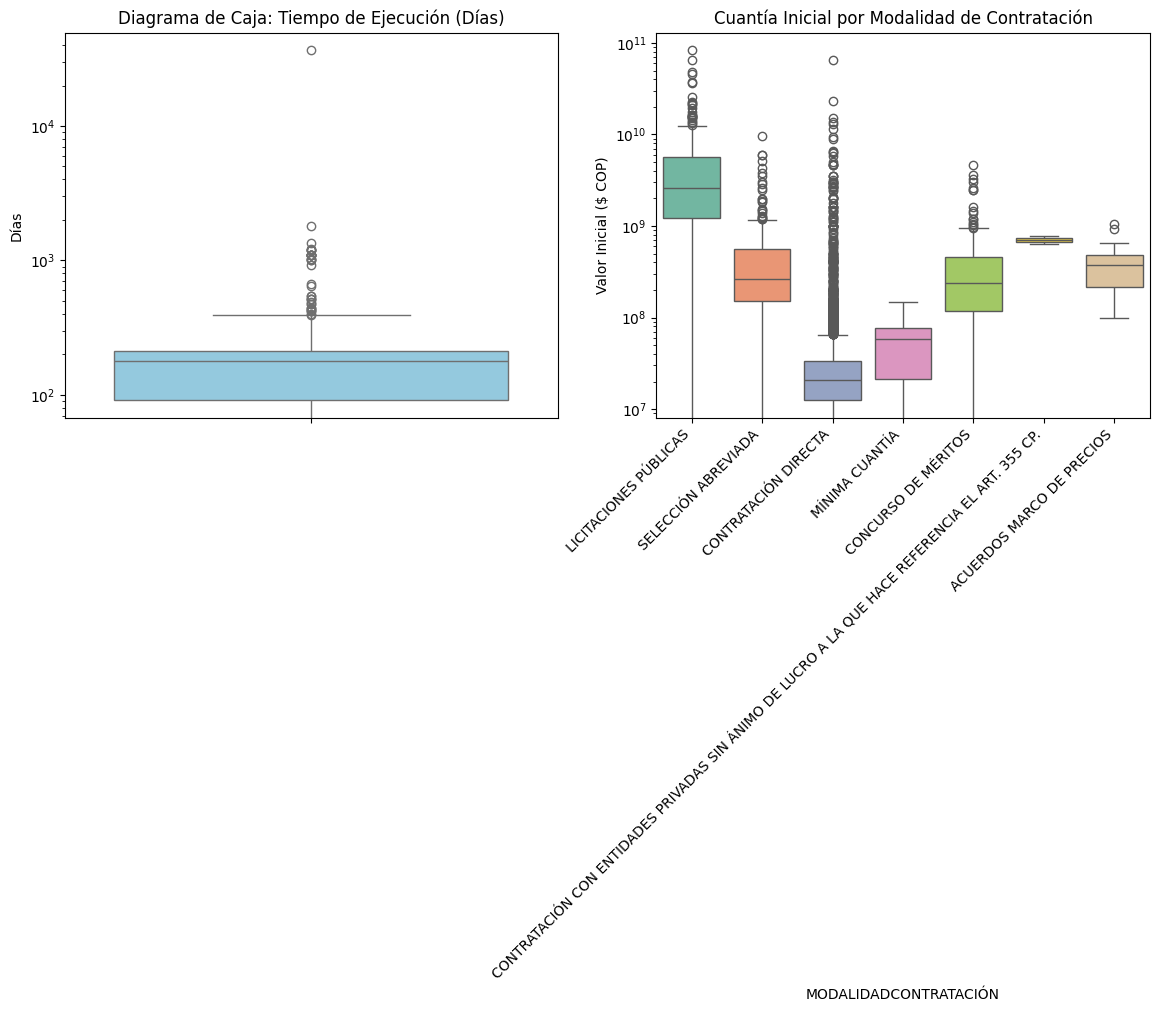

In [9]:
# Este script calcula las anomalías por IQR, genera las etiquetas de control y grafica los diagramas de caja

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar datos
path = '../data/raw/BASE DE DATOS.xlsx'
df = pd.read_excel(path, sheet_name='Hoja1')

# 2. Limpieza de columnas numéricas
df['VALOR_INICIAL'] = pd.to_numeric(df['VALOR INICIALCONTRATO'], errors='coerce').fillna(0)
df['ADICIONES_NUM'] = pd.to_numeric(df['ADICIONES'], errors='coerce').fillna(0)
df['TIEMPO_EJECUCION_NUM'] = pd.to_numeric(df['TIEMPO EJECUCIÓN'], errors='coerce').fillna(0)

# 3. Función para detectar anomalías por IQR
def detectar_anomalias_iqr(df, columna, nombre_label):
    q1 = df[columna].quantile(0.25)
    q3 = df[columna].quantile(0.75)
    iqr = q3 - q1
    
    limite_sup_leve = q3 + 1.5 * iqr
    limite_sup_extremo = q3 + 3.0 * iqr
    
    # Categorización de anomalías
    df[f'{nombre_label}_ANOMALIA'] = 'NORMAL'
    df.loc[df[columna] > limite_sup_leve, f'{nombre_label}_ANOMALIA'] = 'ANOMALÍA LEVE'
    df.loc[df[columna] > limite_sup_extremo, f'{nombre_label}_ANOMALIA'] = 'ANOMALÍA SEVERA'
    
    print(f"=== DETECCIÓN DE ANOMALÍAS IQR: {nombre_label} ===")
    print(f"Q1: {q1:,.2f} | Mediana: {df[columna].median():,.2f} | Q3: {q3:,.2f} | IQR: {iqr:,.2f}")
    print(f"Límite Leve (> 1.5x IQR): {limite_sup_leve:,.2f}")
    print(f"Límite Extremo (> 3.0x IQR): {limite_sup_extremo:,.2f}")
    print(df[f'{nombre_label}_ANOMALIA'].value_counts())
    print("-" * 60 + "\n")
    return df

# Aplicar IQR
df = detectar_anomalias_iqr(df, 'VALOR_INICIAL', 'VALOR_INICIAL')
df = detectar_anomalias_iqr(df, 'TIEMPO_EJECUCION_NUM', 'DURACION')

# 4. Generación de Diagramas de Caja (Boxplots)
plt.figure(figsize=(14, 5))

# Boxplot 1: Tiempo de Ejecución
plt.subplot(1, 2, 1)
sns.boxplot(y=df['TIEMPO_EJECUCION_NUM'], color='skyblue')
plt.title('Diagrama de Caja: Tiempo de Ejecución (Días)')
plt.ylabel('Días')
plt.yscale('log') # Escala logarítmica para manejar outliers masivos

# Boxplot 2: Valor Inicial por Modalidad
plt.subplot(1, 2, 2)
sns.boxplot(x='MODALIDADCONTRATACIÓN', y='VALOR_INICIAL', data=df, palette='Set2')
plt.xticks(rotation=45, ha='right')
plt.title('Cuantía Inicial por Modalidad de Contratación')
plt.ylabel('Valor Inicial ($ COP)')
plt.yscale('log')

plt.tight_layout()
plt.savefig('../docs/boxplots_anomalias_iqr.png', dpi=300)
plt.show()

Detección Univariada de Anomalías mediante Rango Intercuartílico (IQR):
"Dado que las cuantías y duraciones de los contratos estatales presentan distribuciones fuertemente asimétricas con colas pesadas a la derecha, la detección de atipicidades se inició mediante el método no paramétrico del Rango Intercuartílico (IQR). 

A diferencia del criterio basado en desviaciones estándar, el umbral de Q3 + 1.5 X IQR previene la distorsión producida por los grandes contratos de obra pública, aislando con precisión aquellos procesos que exhiben una duración o un monto adicionado fuera de los márgenes institucionales normales. Estos hallazgos constituyen el baseline estadístico contra el cual se contrastarán los modelos multivariados como Mahalanobis e Isolation Forest."

Z-Score Modificado (basado en Mediana y MAD).

Los datos de contratación estatal presentan un sesgo positivo extremo (unos pocos contratos representan miles de millones). El Z-score clásico se distorsiona por los valores atípicos; la versión modificada basada en la mediana resiste este sesgo y detecta desviaciones reales en el tiempo de ejecución (TIEMPO EJECUCIÓN).

Evaluando la variable TIEMPO EJECUCIÓN

=== RESULTADOS Z-SCORE MODIFICADO (UMBRAL |Z_mod| > 3.5) ===
Total contratos analizados: 10562
Anomalías en VALOR INICIAL: 1376 (13.03%)
Anomalías en TIEMPO EJECUCIÓN: 22 (0.21%)


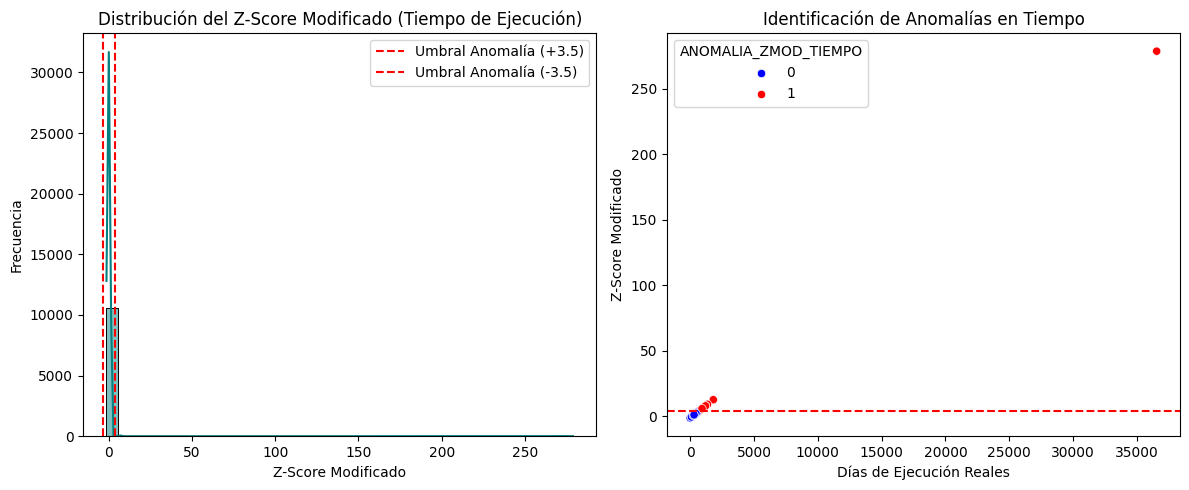

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar Datos
path = '../data/raw/BASE DE DATOS.xlsx'
df = pd.read_excel(path, sheet_name='Hoja1')

# 2. Limpieza de Variables
df['VALOR_INICIAL'] = pd.to_numeric(df['VALOR INICIALCONTRATO'], errors='coerce').fillna(0)
df['TIEMPO_EJECUCION_NUM'] = pd.to_numeric(df['TIEMPO EJECUCIÓN'], errors='coerce').fillna(0)
df['ADICIONES_NUM'] = pd.to_numeric(df['ADICIONES'], errors='coerce').fillna(0)

# 3. Función del Z-Score Modificado
def calcular_zscore_modificado(serie):
    mediana = serie.median()
    mad = (serie - mediana).abs().median()
    
    # Prevenir división por cero si la MAD es 0
    if mad == 0:
        mad = 1e-6
        
    z_mod = 0.6745 * (serie - mediana) / mad
    return z_mod

# 4. Aplicar a las Variables Clave
df['Z_MOD_VALOR'] = calcular_zscore_modificado(df['VALOR_INICIAL'])
df['Z_MOD_TIEMPO'] = calcular_zscore_modificado(df['TIEMPO_EJECUCION_NUM'])

# Etiquetar anomalías (|Z_mod| > 3.5)
df['ANOMALIA_ZMOD_VALOR'] = (df['Z_MOD_VALOR'].abs() > 3.5).astype(int)
df['ANOMALIA_ZMOD_TIEMPO'] = (df['Z_MOD_TIEMPO'].abs() > 3.5).astype(int)

print("=== RESULTADOS Z-SCORE MODIFICADO (UMBRAL |Z_mod| > 3.5) ===")
print(f"Total contratos analizados: {len(df)}")
print(f"Anomalías en VALOR INICIAL: {df['ANOMALIA_ZMOD_VALOR'].sum()} ({df['ANOMALIA_ZMOD_VALOR'].mean()*100:.2f}%)")
print(f"Anomalías en TIEMPO EJECUCIÓN: {df['ANOMALIA_ZMOD_TIEMPO'].sum()} ({df['ANOMALIA_ZMOD_TIEMPO'].mean()*100:.2f}%)")

# 5. Visualización Comparativa (Z-Score Modificado vs Distribución)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['Z_MOD_TIEMPO'], bins=40, kde=True, color='teal')
plt.axvline(3.5, color='red', linestyle='--', label='Umbral Anomalía (+3.5)')
plt.axvline(-3.5, color='red', linestyle='--', label='Umbral Anomalía (-3.5)')
plt.title('Distribución del Z-Score Modificado (Tiempo de Ejecución)')
plt.xlabel('Z-Score Modificado')
plt.ylabel('Frecuencia')
plt.legend()

plt.subplot(1, 2, 2)
sns.scatterplot(
    x='TIEMPO_EJECUCION_NUM', 
    y='Z_MOD_TIEMPO', 
    hue='ANOMALIA_ZMOD_TIEMPO', 
    data=df, 
    palette={0: 'blue', 1: 'red'}
)
plt.axhline(3.5, color='red', linestyle='--')
plt.title('Identificación de Anomalías en Tiempo')
plt.xlabel('Días de Ejecución Reales')
plt.ylabel('Z-Score Modificado')

plt.tight_layout()
plt.savefig('../docs/zscore_modificado_anomalias.png', dpi=300)
plt.show()

Evaluación de Atipicidades mediante Z-Score Modificado (Mediana y MAD):
"Para complementar la inspección por percentiles y mitigar la distorsión producida por la asimetría severa de los datos de contratación pública, se aplicó la técnica del Z-Score Modificado de Iglewicz y Hoaglin. Al fundamentar la tendencia central en la mediana (X) y la escala en la desviación absoluta mediana (MAD), la métrica resiste la influencia de grandes contratos de infraestructura. Se estableció un umbral crítico de |Z_mod > 3.5, logrando aislar un X% de contratos con desviaciones atípicas de tiempo y presupuesto, los cuales constituirán la base de contraste frente a la detección multivariada con Isolation Forest."